**Disciplina:** Tópicos Especiais de Energia – Transferência de Calor utilizando PINNs (UFABC, 3º quadrimestre de 2026)
**Professores:** Prof. Dr. Daniel Jonas Dezan e Prof. MSc. Paulo de Souza Silva
**Aluno:** _preencher com o nome completo_
**Lista 2 – Condução e Solução de Blasius em Python**

Obs.: notebook desenvolvido com auxílio de ferramentas de IA, como permitido no enunciado; o código e os resultados foram executados e conferidos.

# **Exercício 3 – Distribuição bidimensional de temperatura: solução analítica e diferenças finitas**

**Notebook de apoio:** `Aula03_Parte2_2D_Estacionario.ipynb`

## **Enunciado (resumo)**

Placa retangular sem geração, em regime permanente, com $L = 2$ m (direção $x$) e $W = 1$ m (direção $y$). As faces laterais e a inferior estão em $T_1 = 350$ K e a face superior em $T_2 = 650$ K.

Com $\theta = (T-T_1)/(T_2-T_1)$, a solução analítica truncada com $N$ termos é

$$
\theta_N(x,y) = \frac{2}{\pi}\sum_{n=1}^{N}\frac{1-(-1)^n}{n}\,
\sin\!\left(\frac{n\pi x}{L}\right)\frac{\sinh(n\pi y/L)}{\sinh(n\pi W/L)},
\qquad T_N = T_1 + (T_2-T_1)\,\theta_N .
$$

Como $1-(-1)^n = 0$ para $n$ par, apenas os termos ímpares contribuem.

In [1]:
# Bibliotecas utilizadas
import os
import numpy as np                  # funções matemáticas e vetores
import matplotlib.pyplot as plt     # gráficos

os.makedirs("figuras", exist_ok=True)   # pasta onde as figuras são salvas
plt.rcParams["figure.dpi"] = 110
import pandas as pd

## Geometria e temperaturas prescritas
L = 2.0       # comprimento da placa em x [m]
W = 1.0       # altura da placa em y [m]
T1 = 350.0    # faces x = 0, x = L e y = 0 [K]
T2 = 650.0    # face y = W [K]

x_centro, y_centro = L / 2, W / 2

def theta_analitica(x, y, n_termos):
    # Solução analítica truncada com n_termos (código do notebook de apoio)
    theta = np.zeros_like(np.asarray(x, dtype=float))
    for n in range(1, n_termos + 1):
        coeficiente = (2 / np.pi) * (1 - (-1) ** n) / n
        theta += (coeficiente
                  * np.sin(n * np.pi * x / L)
                  * np.sinh(n * np.pi * y / L)
                  / np.sinh(n * np.pi * W / L))
    return theta

def temperatura_analitica(x, y, n_termos):
    return T1 + (T2 - T1) * theta_analitica(x, y, n_termos)

## **Item a)** Temperatura no centro $(L/2,\,W/2)$ para diferentes $N$

In [2]:
termos = [1, 5, 10, 100]
tabela = pd.DataFrame({
    "N (termos)": termos,
    "T(L/2, W/2) [K]": [float(temperatura_analitica(x_centro, y_centro, N)) for N in termos],
})
tabela["Variação vs. N=100 [K]"] = tabela["T(L/2, W/2) [K]"] - tabela["T(L/2, W/2) [K]"].iloc[-1]
print(f"Ponto central: (x, y) = ({x_centro:.1f} m, {y_centro:.1f} m)\n")
print(tabela.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

Ponto central: (x, y) = (1.0 m, 0.5 m)

 N (termos)  T(L/2, W/2) [K]  Variação vs. N=100 [K]
          1         494.1829                 10.6483
          5         483.7271                  0.1926
         10         483.5398                  0.0052
        100         483.5345                  0.0000


Com **um único termo** a temperatura no centro já fica a cerca de 11 K da solução convergida. A partir de $N = 5$ a variação cai para frações de kelvin, e de $N=10$ para $N=100$ muda menos de 0,01 K. No **centro da placa** a série converge rápido, porque o fator $\sinh(n\pi y/L)/\sinh(n\pi W/L)$ decai exponencialmente com $n$ para $y < W$.

## **Item b)** Campo analítico para $N = 1$, $10$ e $100$

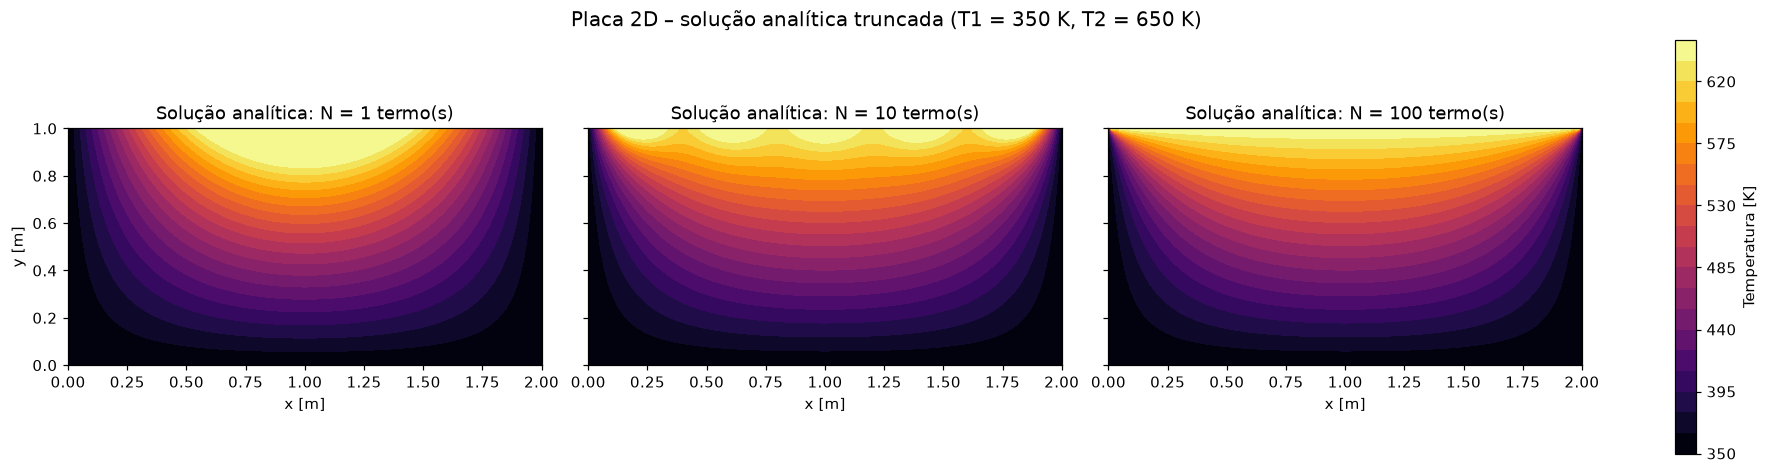

In [3]:
x_plot = np.linspace(0, L, 161)
y_plot = np.linspace(0, W, 81)
X_plot, Y_plot = np.meshgrid(x_plot, y_plot)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharex=True, sharey=True, constrained_layout=True)
niveis = np.linspace(T1, T2, 21)

for ax, N in zip(axes, [1, 10, 100]):
    T_campo = np.clip(temperatura_analitica(X_plot, Y_plot, N), T1, T2)  # recorte só para a escala de cores
    mapa = ax.contourf(X_plot, Y_plot, T_campo, levels=niveis, cmap="inferno")
    ax.set_title(f"Solução analítica: N = {N} termo(s)")
    ax.set_xlabel("x [m]")
    ax.set_aspect("equal")
axes[0].set_ylabel("y [m]")
fig.colorbar(mapa, ax=axes.ravel().tolist(), label="Temperatura [K]")
fig.suptitle("Placa 2D – solução analítica truncada (T1 = 350 K, T2 = 650 K)", fontsize=13)
plt.savefig("figuras/ex3b_analitica_N1_N10_N100.png", dpi=300, bbox_inches="tight")
plt.show()

- **$N=1$:** só o primeiro modo senoidal aparece. A face superior não fica uniforme em 650 K: o perfil é uma "lomba" com máximo em $x=L/2$, e perto dos cantos superiores a temperatura é bem menor que $T_2$.
- **$N=10$ e $N=100$:** a condição $T=T_2$ no topo vai sendo recuperada e os campos ficam praticamente iguais no interior. As diferenças restantes ficam numa faixa estreita junto à face superior e aos cantos superiores. Ali a condição de contorno é **descontínua** (salta de 350 K para 650 K), e a série de senos converge devagar e oscila (fenômeno de Gibbs). Os valores fora de $[T_1, T_2]$ causados por essa oscilação foram recortados apenas para a escala de cores.

## **Item c)** Diferenças finitas com malhas 5×5 e 11×11

Para os pontos internos usamos o estêncil de cinco pontos da equação de Laplace (notebook de apoio):

$$
\left(\frac{2}{\Delta x^2}+\frac{2}{\Delta y^2}\right)T_{i,j}-\frac{T_{i-1,j}+T_{i+1,j}}{\Delta x^2}-\frac{T_{i,j-1}+T_{i,j+1}}{\Delta y^2}=0 .
$$

Os pontos de contorno são conhecidos e vão para o vetor $b$. O código do notebook foi colocado numa função, para rodar as duas malhas sem duplicar o código.

In [4]:
def resolver_diferencas_finitas(Nx, Ny):
    # Montagem e solução do sistema A T = b (código do notebook de apoio)
    x_fd = np.linspace(0, L, Nx)
    y_fd = np.linspace(0, W, Ny)
    dx = x_fd[1] - x_fd[0]
    dy = y_fd[1] - y_fd[0]

    n_internos = (Nx - 2) * (Ny - 2)
    A = np.zeros((n_internos, n_internos))
    b = np.zeros(n_internos)

    def indice(i, j):
        return (j - 1) * (Nx - 2) + (i - 1)

    coef_x = 1 / dx**2
    coef_y = 1 / dy**2
    coef_central = 2 * coef_x + 2 * coef_y

    for j in range(1, Ny - 1):
        for i in range(1, Nx - 1):
            linha = indice(i, j)
            A[linha, linha] = coef_central
            if i == 1:      b[linha] += coef_x * T1              # vizinho à esquerda
            else:           A[linha, indice(i - 1, j)] = -coef_x
            if i == Nx - 2: b[linha] += coef_x * T1              # vizinho à direita
            else:           A[linha, indice(i + 1, j)] = -coef_x
            if j == 1:      b[linha] += coef_y * T1              # vizinho abaixo
            else:           A[linha, indice(i, j - 1)] = -coef_y
            if j == Ny - 2: b[linha] += coef_y * T2              # vizinho acima
            else:           A[linha, indice(i, j + 1)] = -coef_y

    temperaturas_internas = np.linalg.solve(A, b)

    # Campo completo, incluindo as fronteiras (topo em T2, demais em T1)
    T_fd = np.full((Ny, Nx), T1, dtype=float)
    T_fd[-1, :] = T2
    for j in range(1, Ny - 1):
        for i in range(1, Nx - 1):
            T_fd[j, i] = temperaturas_internas[indice(i, j)]

    X_fd, Y_fd = np.meshgrid(x_fd, y_fd)
    return X_fd, Y_fd, T_fd


malhas = {}
for Nx, Ny in [(5, 5), (11, 11)]:
    X_fd, Y_fd, T_fd = resolver_diferencas_finitas(Nx, Ny)
    malhas[(Nx, Ny)] = (X_fd, Y_fd, T_fd)
    T_c = T_fd[Ny // 2, Nx // 2]
    print(f"Malha {Nx}x{Ny}: {Nx*Ny} pontos no total "
          f"({(Nx-2)*(Ny-2)} internos/incógnitas, {Nx*Ny-(Nx-2)*(Ny-2)} de contorno) | "
          f"dx = {X_fd[0,1]-X_fd[0,0]:.3f} m, dy = {Y_fd[1,0]-Y_fd[0,0]:.3f} m | "
          f"T no centro = {T_c:.4f} K")
print(f"\nReferência analítica (N = 100) no centro: {float(temperatura_analitica(x_centro, y_centro, 100)):.4f} K")

Malha 5x5: 25 pontos no total (9 internos/incógnitas, 16 de contorno) | dx = 0.500 m, dy = 0.250 m | T no centro = 478.7805 K
Malha 11x11: 121 pontos no total (81 internos/incógnitas, 40 de contorno) | dx = 0.200 m, dy = 0.100 m | T no centro = 482.6557 K

Referência analítica (N = 100) no centro: 483.5345 K


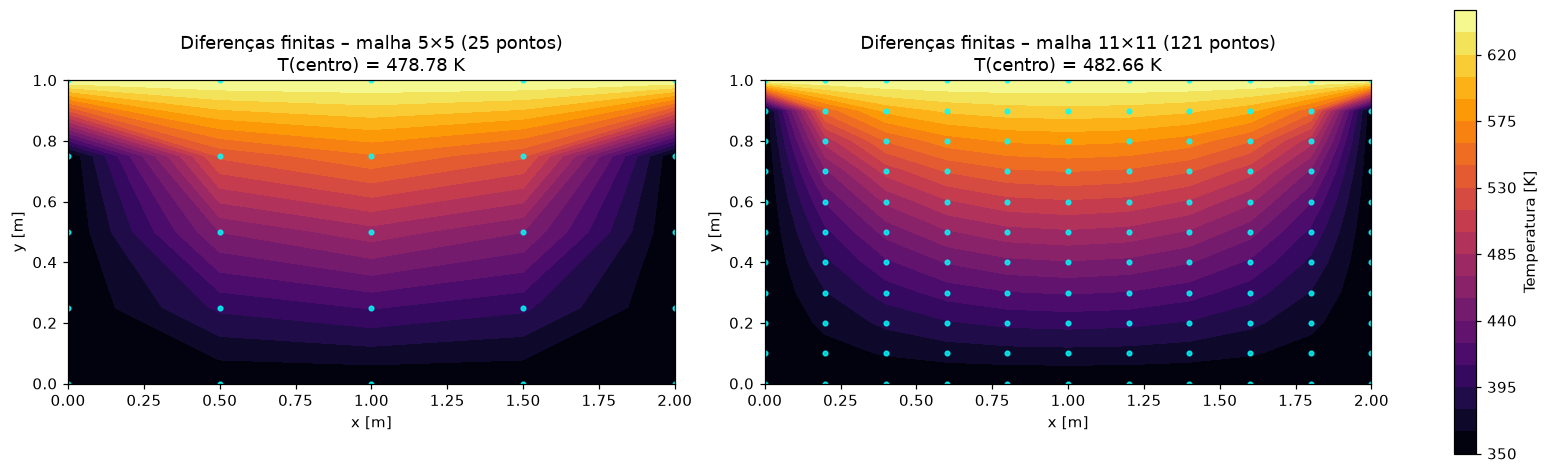

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
niveis = np.linspace(T1, T2, 21)

for ax, (Nx, Ny) in zip(axes, malhas):
    X_fd, Y_fd, T_fd = malhas[(Nx, Ny)]
    mapa = ax.contourf(X_fd, Y_fd, T_fd, levels=niveis, cmap="inferno")
    ax.plot(X_fd, Y_fd, "o", color="cyan", ms=3, alpha=0.8)       # nós da malha
    ax.set_title(f"Diferenças finitas – malha {Nx}×{Ny} ({Nx*Ny} pontos)\n"
                 f"T(centro) = {T_fd[Ny//2, Nx//2]:.2f} K")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_aspect("equal")
fig.colorbar(mapa, ax=axes.ravel().tolist(), label="Temperatura [K]")
plt.savefig("figuras/ex3c_df_5x5_11x11.png", dpi=300, bbox_inches="tight")
plt.show()

- Na malha **5×5** há só 9 incógnitas. O campo tem o formato certo (quente no topo, frio nas demais faces), mas as isotermas são grosseiras, porque o `contourf` interpola linearmente entre poucos nós.
- Na malha **11×11** (81 incógnitas) o campo já é suave e muito parecido com o analítico. A temperatura no centro se aproxima da referência: 478,78 K na 5×5 e 482,66 K na 11×11, contra 483,53 K da série com $N=100$.

## **Item d)** Malha 11×11: analítica ($N=100$) × diferenças finitas × erro absoluto

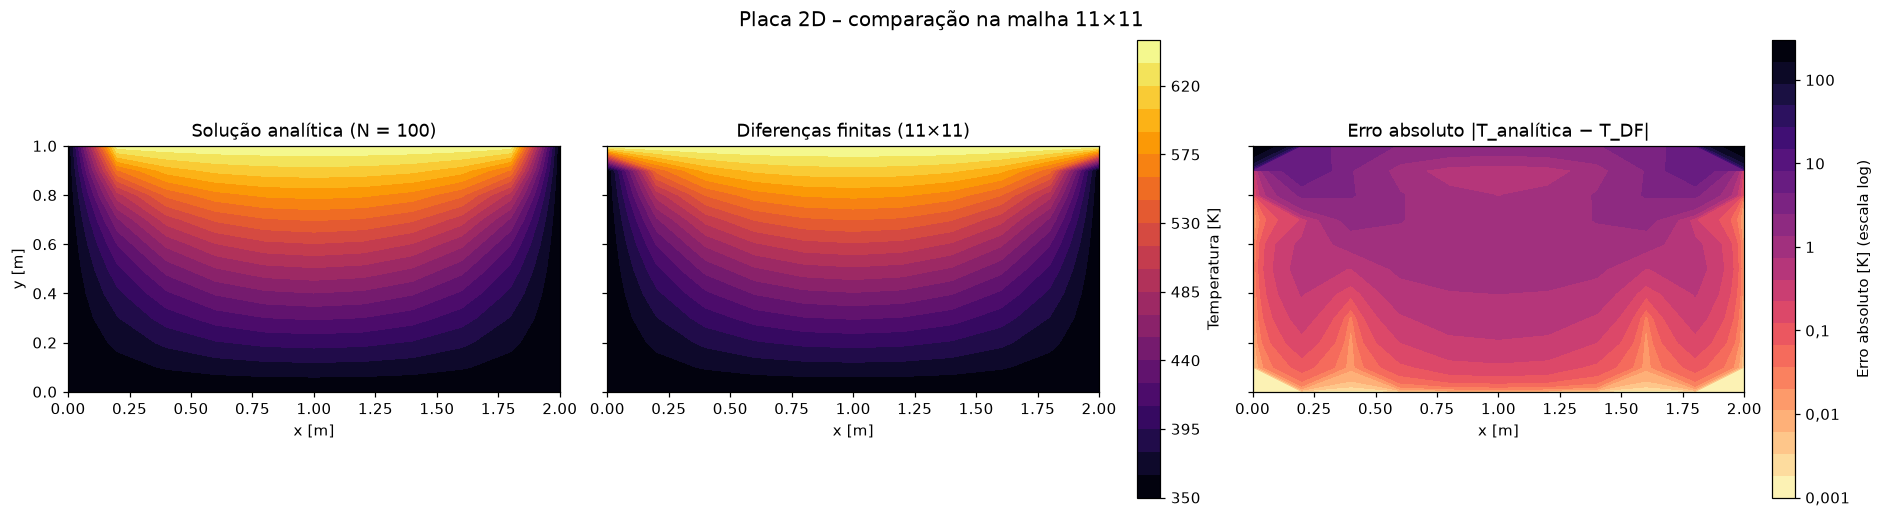

Erro máximo (todos os 121 nós):      300.0000 K
Erro médio  (todos os 121 nós):      5.8050 K
  -> o máximo ocorre em (x, y) = (0.0, 1.0) m (canto superior)
Erro máximo (81 nós internos):       7.4533 K
Erro médio  (81 nós internos):       0.9004 K


In [6]:
X_fd, Y_fd, T_fd = malhas[(11, 11)]
T_analitica_ref = temperatura_analitica(X_fd, Y_fd, 100)
erro_absoluto = np.abs(T_analitica_ref - T_fd)

niveis_T = np.linspace(T1, T2, 21)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharex=True, sharey=True, constrained_layout=True)

m0 = axes[0].contourf(X_fd, Y_fd, np.clip(T_analitica_ref, T1, T2), levels=niveis_T, cmap="inferno")
axes[0].set_title("Solução analítica (N = 100)")
m1 = axes[1].contourf(X_fd, Y_fd, T_fd, levels=niveis_T, cmap="inferno")
axes[1].set_title("Diferenças finitas (11×11)")
# erro em escala logarítmica: os cantos superiores (300 K) dominariam uma escala linear
from matplotlib.colors import LogNorm
niveis_erro = np.logspace(-3, np.log10(erro_absoluto.max()), 22)
m2 = axes[2].contourf(X_fd, Y_fd, np.maximum(erro_absoluto, 1e-3), levels=niveis_erro,
                      norm=LogNorm(), cmap="magma_r")
axes[2].set_title("Erro absoluto |T_analítica − T_DF|")

for ax in axes:
    ax.set_xlabel("x [m]")
    ax.set_aspect("equal")
axes[0].set_ylabel("y [m]")
fig.colorbar(m1, ax=axes[:2], label="Temperatura [K]", pad=0.02)
cb = fig.colorbar(m2, ax=axes[2], label="Erro absoluto [K] (escala log)", pad=0.02,
                  ticks=[1e-3, 1e-2, 1e-1, 1, 10, 100])
cb.ax.set_yticklabels(["0,001", "0,01", "0,1", "1", "10", "100"])
fig.suptitle("Placa 2D – comparação na malha 11×11", fontsize=13)
plt.savefig("figuras/ex3d_comparacao_11x11.png", dpi=300, bbox_inches="tight")
plt.show()

interno = (slice(1, -1), slice(1, -1))
print(f"Erro máximo (todos os 121 nós):      {erro_absoluto.max():.4f} K")
print(f"Erro médio  (todos os 121 nós):      {erro_absoluto.mean():.4f} K")
j_max, i_max = np.unravel_index(erro_absoluto.argmax(), erro_absoluto.shape)
print(f"  -> o máximo ocorre em (x, y) = ({X_fd[j_max, i_max]:.1f}, {Y_fd[j_max, i_max]:.1f}) m (canto superior)")
print(f"Erro máximo (81 nós internos):       {erro_absoluto[interno].max():.4f} K")
print(f"Erro médio  (81 nós internos):       {erro_absoluto[interno].mean():.4f} K")

## **Observações**

- **Visualmente**, os campos analítico e numérico são muito parecidos: mesmas isotermas, aquecimento concentrado junto à face superior e simetria em torno de $x = L/2$.
- O **erro máximo** (300 K) aparece nos **cantos superiores**, $(0, W)$ e $(L, W)$. Não é erro do método: ali a condição de contorno é ambígua. A face lateral pede 350 K e o topo pede 650 K. O código de DF atribui $T_2$ ao canto, enquanto a série de senos vale exatamente $T_1$ em $x=0$ e $x=L$. Esse único ponto infla o erro médio.
- Ao longo da face superior, a série com $N=100$ também oscila em torno de 650 K (Gibbs), o que gera erros de alguns kelvin nessa linha.
- Considerando só os **nós internos** (onde as duas soluções resolvem de fato a mesma equação), o erro máximo cai para cerca de 7 K, junto aos cantos superiores, e o erro médio para menos de 1 K. Refinar a malha reduziria esses valores (erro $\mathcal{O}(\Delta x^2)$), como já indica a temperatura no centro.